# **Practical 10 — Weight Initialization and CNN Visualization**

**Training and Understanding CNNs in PyTorch**

**Topics:** LeCun • Xavier • He • Filters • Feature Maps • Saliency • Integrated Gradients • Guided Backprop • Grad-CAM • Occlusion

### Aim
1. **Experiment 1:** Write LeCun, Xavier and He weight initialization from scratch, match them with `torch.nn.init`, and measure what each one does to the signal and to training in a six-layer CNN.
2. **Experiment 2:** Train the same CNN and look inside it using filters, feature maps and attribution methods (Captum).

### Dataset
CIFAR-10: 32×32 RGB images in 10 classes.

## **Step 0 — Setup**

The laboratory manual requires Python 3.9+, `torch`, `torchvision`, `matplotlib` and `captum`.  
A CPU is enough; a GPU (Colab: Runtime → Change runtime type → T4 GPU) makes the training cells faster.

Captum is not installed in Colab by default, so the first cell installs it.

In [ ]:
# Install Captum (PyTorch's interpretability library)
# -q = quiet, so the install does not print pages of text
!pip install -q captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 19.0 MB/s eta 0:00:00


In [ ]:
# -------------------- IMPORT LIBRARIES --------------------

import math
import time

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms

# make_grid tiles many small images into one picture
from torchvision.utils import make_grid

import matplotlib.pyplot as plt


# Set random seed so that results are more reproducible
torch.manual_seed(0)


# Use GPU if CUDA is available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.11.0+cu130 | device: cuda


# **Experiment 1 — Weight Initialization**

### Aim
See how the starting weights control the size of the signal as it passes through a deep CNN, and write the three standard initializers yourself before using PyTorch's own.

### Why the starting variance matters
A convolution output is a weighted sum of `n_in` inputs (`n_in` = fan-in). If weights and inputs are independent with zero mean:

**Var(output) = n_in × Var(w) × Var(input)**

After L layers this factor is applied L times. A factor of exactly **1** keeps the signal steady; anything else compounds (0.9 per layer leaves about 4% of the variance after 30 layers, 1.1 per layer multiplies it by about 17).

### The three rules

| Scheme | Weight variance | Uniform bound a = √(3·Var) |
|---|---|---|
| LeCun | 1 / n_in | √(3 / n_in) |
| Xavier (Glorot) | 2 / (n_in + n_out) | √(6 / (n_in + n_out)) |
| He (Kaiming) | 2 / n_in | √(6 / n_in) |

- **LeCun:** Var(w) = 1/n_in makes n_in · Var(w) exactly 1 for a linear layer.
- **Xavier:** the forward pass wants 1/n_in, the backward pass wants 1/n_out, so Xavier takes the compromise 2/(n_in + n_out).
- **He:** a ReLU zeroes the negative half of its input and halves the mean square, so doubling the variance to 2/n_in cancels the loss.
- **Normal vs uniform:** U(−a, a) has variance a²/3, so the same variance needs a = √(3·Var). Same variance, different shape.

## **1.1 — Fan-in and Fan-out**

**Fan-in** = number of weights feeding ONE output value = kernel height × kernel width × input channels.  
**Fan-out** = number of weights that ONE input value feeds into = kernel area × output channels.

The function below reads both from a weight tensor and works for `Conv2d` and `Linear` layers.

In [ ]:
# ==========================================================
# FUNCTION: FAN-IN AND FAN-OUT
# ==========================================================

def fans(w):
    # Fan-in and fan-out of a Conv2d or Linear weight tensor.
    #
    # Conv2d weight shape : (out_channels, in_channels, kH, kW)
    # Linear weight shape : (out_features, in_features)

    # w[0] is ALL the weights of the first output filter.
    # numel() counts them  ->  in_channels x kH x kW
    # These are the weights that feed ONE output value.
    n_in = w[0].numel()

    # w[0, 0] is one kernel of one input channel -> kH x kW (kernel area)
    # (for a Linear layer it is a single number, so the area is 1)
    # kernel area x number of output channels = fan-out
    n_out = w.shape[0] * w[0, 0].numel()

    return n_in, n_out


# A 5x5 convolution, 16 input channels -> 32 output channels
conv = nn.Conv2d(16, 32, 5)
# conv.weight.data: This accesses the weight tensor of the convolutional layer.
# total number of weights is: 32x16x5x5=12,800

print("fan_in, fan_out :", fans(conv.weight.data))

# PyTorch has its own private helper for the same job
# # PyTorch calculates fan_in/fan_out for comparison, then numel()
# counts all weights and biases to get total trainable parameters.
print("PyTorch agrees  :", nn.init._calculate_fan_in_and_fan_out(conv.weight))

# Total number of parameters (weights + biases)
print("parameters      :", sum(p.numel() for p in conv.parameters()))

fan_in, fan_out : (400, 800)
PyTorch agrees  : (400, 800)
parameters      : 12832


| Code | Meaning |
|---|---|
| `conv.weight` | The weight parameter tracked by PyTorch's autograd system for gradient computation. |
| `conv.weight.data` | Accesses the underlying tensor data while bypassing normal autograd tracking safeguards. |

**Checks by hand**
- fan-in = 5 × 5 × 16 = **400**
- fan-out = 5 × 5 × 32 = **800**
- parameters = (5 × 5 × 16 + 1) × 32 = 401 × 32 = **12,832**

The layer holds 12,832 parameters, but the number that goes into every initialization formula is **400**. Using the parameter count (about 32 times larger) would make the weights about √32 ≈ **5.7 times too small**.

## **1.2 — LeCun, Xavier and He from Scratch**

Each initializer needs only the fans and a way to fill a tensor with random numbers of a chosen variance. The `fill` function is written once, and each scheme is then two lines.

The functions change the tensor **in place** (note the underscore in `normal_` and `uniform_`), so they are given `layer.weight.data` and not `layer.weight`.

In [ ]:
# ==========================================================
# THE FILLING FUNCTION
# ==========================================================

def fill(w, var, uniform=False):
    # Fill tensor w with zero-mean random numbers of variance var.

    if uniform:
        # U(-a, a) has variance a^2 / 3
        # So for a wanted variance:  a = sqrt(3 * var)
        a = math.sqrt(3 * var)
        w.uniform_(-a, a)
    else:
        # Normal distribution: std = sqrt(variance)
        w.normal_(0, math.sqrt(var))


# ==========================================================
# THE THREE INITIALIZERS
# ==========================================================

def lecun_init(w, uniform=False):
    n_in, _ = fans(w)              # only fan-in is needed
    fill(w, 1 / n_in, uniform)     # Var(w) = 1 / n_in


def xavier_init(w, uniform=False):
    n_in, n_out = fans(w)                    # both fans are needed
    fill(w, 2 / (n_in + n_out), uniform)     # Var(w) = 2 / (n_in + n_out)


def he_init(w, uniform=False):
    n_in, _ = fans(w)              # only fan-in is needed
    fill(w, 2 / n_in, uniform)     # Var(w) = 2 / n_in

In [ ]:
# --------------------------------------------------
# TEST ON ONE LAYER
# --------------------------------------------------

# A 3x3 convolution from 32 to 64 channels
# n_in  = 3 x 3 x 32 = 288
# n_out = 3 x 3 x 64 = 576
w = nn.Conv2d(32, 64, 3).weight.data

n_in, n_out = fans(w)
print("n_in, n_out =", n_in, n_out)


# (name, function, standard deviation the formula asks for)
schemes = [
    ("LeCun",  lecun_init,  math.sqrt(1 / n_in)),
    ("Xavier", xavier_init, math.sqrt(2 / (n_in + n_out))),
    ("He",     he_init,     math.sqrt(2 / n_in)),
]

print(f"{'method':8s} {'target std':>11s} {'normal':>9s} {'uniform':>9s}")

for name, init, target in schemes:

    # Fill the tensor with the NORMAL version and measure its real std
    # w.std() returns a single-value PyTorch tensor.
    # .item() extracts the number from that tensor.
    init(w)
    normal = w.std().item()

    # Fill the same tensor with the UNIFORM version and measure again
    init(w, uniform=True)
    uniform = w.std().item()

    print(f"{name:8s} {target:11.5f} {normal:9.5f} {uniform:9.5f}")

n_in, n_out = 288 576
method    target std    normal   uniform
LeCun        0.05893   0.05886   0.05868
Xavier       0.04811   0.04835   0.04820
He           0.08333   0.08343   0.08298


### Ready to Explain

**1. Target values (calculated by hand):**
- LeCun: √(1/288) = **0.05893**
- Xavier: √(2/(288 + 576)) = √(2/864) = **0.04811**
- He: √(2/288) = **0.08333**

The normal and uniform columns should both land very close to these targets (last digits vary with the random numbers).

**2. Relations between the schemes:**
- He's std is **√2 times** LeCun's (it doubles the variance).
- Xavier is **smaller** than LeCun here because n_out (576) is larger than n_in (288), which pulls 2/(n_in + n_out) below 1/n_in.
- When n_in = n_out, Xavier = 2/(2·n_in) = 1/n_in, which is exactly LeCun.

**3. Normal vs uniform:** same variance, different shape. The uniform bound is a = √(3·Var) because U(−a, a) has variance a²/3.

## **1.3 — The Same Three with `torch.nn.init`**

PyTorch provides `xavier_normal_`, `xavier_uniform_`, `kaiming_normal_` and `kaiming_uniform_`. **Kaiming is just another name for He.**

There is **no function called lecun**. LeCun is the Kaiming rule with `nonlinearity="linear"`, which sets the gain to 1 and so gives variance 1/n_in.

The cell below fills the same tensor with my function and then with PyTorch's, and prints both standard deviations.

In [ ]:
# ==========================================================
# PYTORCH'S OWN INITIALIZERS
# ==========================================================

# It compares two ways of initializing the weights of a convolutional neural network (CNN):
# 1. Scratch: your own initialization functions (lecun_init, xavier_init, and he_init).
# 2. PyTorch: built-in initialization functions from torch.nn.init.

# It compares three initialization methods — LeCun, Xavier, and He — using two distributions: normal and uniform.
# That gives us 3 x 2 = 6comparisons.
# Key = (scheme name, is it uniform?)
# Value = a function that fills a tensor w using torch.nn.init
inbuilt = {
    # LeCun = Kaiming with the "linear" nonlinearity (gain = 1)
    # gain = root target variance x nin
    # "LeCun" is the initialization method.
    # False means use a normal distribution.
    # True means use a uniform distribution.
    # This defines a small function that accepts a tensor w and initializes it using PyTorch's Kaiming normal initializer with the "linear" setting.
    ("LeCun",  False): lambda w: nn.init.kaiming_normal_(w,  nonlinearity="linear"),
    ("LeCun",  True):  lambda w: nn.init.kaiming_uniform_(w, nonlinearity="linear"),

    # Xavier has its own functions
    # PyTorch's xavier_normal_ function already accepts a weight tensor directly,
    # so we can store the function itself.
    ("Xavier", False): nn.init.xavier_normal_,
    ("Xavier", True):  nn.init.xavier_uniform_,

    # He = Kaiming with the "relu" nonlinearity (gain = sqrt(2))
    ("He",     False): lambda w: nn.init.kaiming_normal_(w,  nonlinearity="relu"),
    ("He",     True):  lambda w: nn.init.kaiming_uniform_(w, nonlinearity="relu"),
}

# My own functions from Section 1.2, looked up by name
scratch = {"LeCun": lecun_init, "Xavier": xavier_init, "He": he_init}


# A 3x3 convolution from 64 to 128 channels
# n_in = 576, n_out = 1152
w = nn.Conv2d(64, 128, 3).weight.data

print(f"{'method':8s} {'shape':8s} {'scratch std':>12s} {'PyTorch std':>12s}")

for (name, uniform), torch_init in inbuilt.items():

    # Fill with MY function and measure the std
    scratch[name](w, uniform)
    mine = w.std().item()

    # Fill the same tensor with PyTorch's function and measure the std
    # torch_init holds the PyTorch function selected by the current dictionary entry.
    torch_init(w)
    theirs = w.std().item()

    print(f"{name:8s} {'uniform' if uniform else 'normal':8s} {mine:12.5f} {theirs:12.5f}")

method   shape     scratch std  PyTorch std
LeCun    normal        0.04159      0.04169
LeCun    uniform       0.04169      0.04174
Xavier   normal        0.03393      0.03397
Xavier   uniform       0.03405      0.03395
He       normal        0.05900      0.05891
He       uniform       0.05887      0.05900


### Ready to Explain

**1. Do they match?** Yes. For every row the scratch std and PyTorch std agree to about 2–3 significant digits. Target values for this layer: LeCun √(1/576) = **0.04167**, Xavier √(2/1728) = **0.03402**, He √(2/576) = **0.05893**.

**2. How do we get LeCun in PyTorch?** `kaiming_normal_(w, nonlinearity="linear")` (or `kaiming_uniform_`). Gain = 1, so Var = 1/n_in.

**3. The default is NOT He:**
- A freshly built `nn.Conv2d` is initialized with `kaiming_uniform_(w, a=math.sqrt(5))`.
- That gives gain = √(2/(1 + 5)) = √(1/3), so std = 1/√(3·n_in).
- This is **√6 ≈ 2.45 times narrower** than He.
- Shallow networks barely notice; deep plain ReLU stacks do, as Section 1.4 shows. If you want He, call the initializer yourself.

## **1.4 — What the Initializer Does to a Deep CNN**

Now the initializers are put inside a real network: **six 3×3 convolutions with ReLU and no BatchNorm**, so nothing hides the effect.

- `apply_init` applies an initializer to every layer. `model.apply(fn)` is the standard PyTorch way to run a function on every sub-module.
- A random input is passed through the network and the **root-mean-square (RMS)** of the activations is recorded after every ReLU.
- RMS is used because the theory preserves the *mean square*, and a ReLU output has a non-zero mean.
- The result is plotted on a **log scale**.

scheme               relu1     relu2     relu3     relu4     relu5     relu6
PyTorch default   3.98e-01  1.50e-01  9.85e-02  3.64e-02  1.98e-02  7.86e-03
LeCun             6.88e-01  4.59e-01  4.19e-01  2.61e-01  2.50e-01  1.60e-01
Xavier            2.85e-01  1.90e-01  1.42e-01  8.83e-02  6.89e-02  4.41e-02
He                9.73e-01  9.19e-01  1.19e+00  1.04e+00  1.41e+00  1.28e+00
std = 0.01        3.58e-02  4.05e-03  6.28e-04  9.38e-05  2.15e-05  4.67e-06


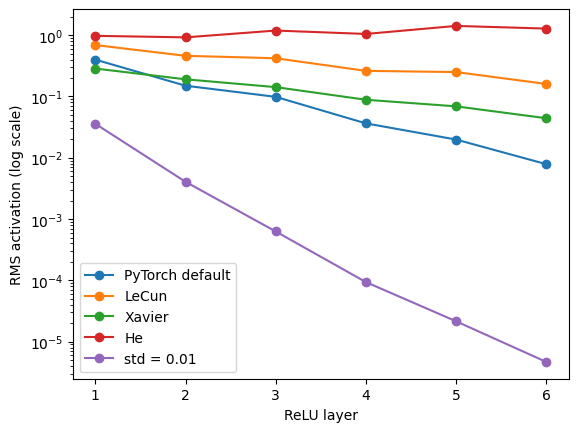

In [ ]:
# ==========================================================
# FUNCTION: APPLY AN INITIALIZER TO A WHOLE MODEL
# ==========================================================

def apply_init(model, init_fn):
    # model = the CNN model
    # init_fn = the initialization function to use (LeCun, Xavier, He, etc.)

    def init_layer(m):
        # m represents one individual layer in the model

        # Initialize only convolutional and fully connected layers
        if isinstance(m, (nn.Conv2d, nn.Linear)):

            # Initialize the layer's weights using the selected function
            init_fn(m.weight.data)

            # Set all bias values of this layer to zero
            m.bias.data.zero_()

    # Visit every module in the model and apply init_layer to it
    model.apply(init_layer)

    # Return the model after initialization
    return model


# ==========================================================
# THE CNN USED IN BOTH EXPERIMENTS
# ==========================================================

class CNN(nn.Module):
    # Define a CNN with six convolutional layers and no BatchNorm

    def __init__(self):
        # Initialize the parent nn.Module class
        super().__init__()

        # Channel counts for the six convolutional layers:
        # Conv1: 3  -> 32
        # Conv2: 32 -> 32
        # Conv3: 32 -> 64
        # Conv4: 64 -> 64
        # Conv5: 64 -> 128
        # Conv6: 128 -> 128
        ch = [3, 32, 32, 64, 64, 128, 128]

        # Empty list to store the CNN's layers in order
        layers = []

        # Repeat six times to create six convolutional layers
        for i in range(6):

            # Create a 3x3 convolutional layer
            # ch[i] = input channels
            # ch[i+1] = output channels
            # padding=1 keeps height and width unchanged
            layers += [
                nn.Conv2d(ch[i], ch[i + 1], 3, padding=1),

                # Apply ReLU activation after the convolution
                nn.ReLU()
            ]

            # After Conv2, Conv4, and Conv6, add max-pooling
            # i = 1, 3, 5 satisfy this condition
            if i % 2 == 1:

                # Reduce height and width by half
                # Example: 32x32 -> 16x16
                layers.append(nn.MaxPool2d(2))

        # Combine all convolution, ReLU, and pooling layers
        # The * unpacks the list into individual arguments
        self.features = nn.Sequential(*layers)

        # Final classifier:
        # After pooling, the feature map has shape 128x4x4
        # Flatten it: 128*4*4 = 2048 features per image
        # Convert the 2048 features into 10 class scores
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 10)
        )

    def forward(self, x):
        # Pass the input through the convolutional feature extractor
        x = self.features(x)

        # Pass the extracted features to the classifier
        x = self.classifier(x)

        # Return the 10 output scores for each image
        return x


# ==========================================================
# THE FIVE INITIALIZATION CHOICES TO COMPARE
# ==========================================================

inits = {
    # PyTorch's usual default initialization for Conv2d/Linear weights
    # Kaiming uniform with a=sqrt(5)
    "PyTorch default": lambda w: nn.init.kaiming_uniform_(
        w, a=math.sqrt(5)
    ),

    # Use our custom LeCun initialization function
    "LeCun": lecun_init,

    # Use our custom Xavier initialization function
    "Xavier": xavier_init,

    # Use our custom He initialization function
    "He": he_init,

    # Baseline example: normal distribution with mean 0 and std 0.01
    # w is the weight tensor being initialized
    "std = 0.01": lambda w: w.normal_(0, 0.01),
}


# ==========================================================
# FUNCTION: MEASURE ACTIVATION STRENGTH AFTER EVERY RELU
# ==========================================================

def activation_scales(init_fn):
    # init_fn specifies which weight initialization method to test

    # Reset the random seed so each experiment starts reproducibly
    torch.manual_seed(0)

    # Create a fresh CNN, initialize its weights, and set evaluation mode
    model = apply_init(CNN(), init_fn).eval()

    # Generate 64 random RGB images of size 32x32
    # Shape: (batch_size, channels, height, width)
    h = torch.randn(64, 3, 32, 32)

    # Empty list to store the RMS activation after each ReLU
    scales = []

    # No gradients are needed because we are not training the model
    with torch.no_grad():

        # Visit each layer in the CNN's feature extractor in order
        for layer in model.features:

            # Pass the current activations through the current layer
            # The output becomes the input to the next layer
            h = layer(h)

            # Record a measurement only after a ReLU layer
            if isinstance(layer, nn.ReLU):

                # Square every activation value
                # Calculate the mean of the squared values
                # Take the square root to obtain RMS
                # Convert the scalar tensor into a Python number
                rms = h.pow(2).mean().sqrt().item()

                # Store this ReLU layer's RMS activation
                scales.append(rms)

    # Return six measurements: one after each ReLU
    return scales


# ==========================================================
# PRINT THE TABLE HEADER
# ==========================================================

# Print the initialization scheme followed by relu1, relu2, ..., relu6
# :16s means a string field 16 characters wide
# :>10s means right-align a string in a 10-character-wide field
print(
    f"{'scheme':16s}"
    + "".join(
        f"{'relu' + str(i + 1):>10s}"
        for i in range(6)
    )
)


# ==========================================================
# RUN THE EXPERIMENT FOR ALL FIVE INITIALIZATION METHODS
# ==========================================================

# Loop through each name and initialization function in the dictionary
for name, fn in inits.items():

    # Run the experiment with this initializer
    # Returns six RMS activation measurements
    s = activation_scales(fn)

    # Print the scheme name and its six RMS values
    # .2e displays each value in scientific notation
    print(
        f"{name:16s}"
        + "".join(f"{v:10.2e}" for v in s)
    )

    # Plot the six RMS measurements against ReLU layers 1 through 6
    # semilogy uses a logarithmic scale on the y-axis
    # marker="o" places a circle at each measurement
    # label=name identifies the method in the legend
    plt.semilogy(
        range(1, 7),
        s,
        marker="o",
        label=name
    )


# ==========================================================
# FORMAT AND DISPLAY THE GRAPH
# ==========================================================

# Label the horizontal axis
plt.xlabel("ReLU layer")

# Label the vertical axis
plt.ylabel("RMS activation (log scale)")

# Display labels for all five initialization methods
plt.legend()

# Display the completed graph
plt.show()

### Ready to Explain

**1. What should the table show?**
- **He:** the RMS stays close to **1** through all six layers, because its factor of 2 cancels the ReLU's halving.
- **LeCun:** loses roughly a quarter to a third of the scale per layer. Nothing compensates for the ReLU zeroing half the signal.
- **Xavier:** decays faster than LeCun. At layers where the channel count grows, n_out > n_in, so 2/(n_in + n_out) falls below 1/n_in. That compromise suits tanh, not ReLU.
- **PyTorch default:** √6 times narrower than He, so the RMS falls from about 0.4 at relu1 to about 8e-3 at relu6 (roughly 50 times down, and over 100 times below the input scale of 1).
- **std = 0.01:** the instructive failure. The scale collapses by hundreds of thousands of times by the sixth ReLU and the classifier sees essentially zeros. No formula produced that number; somebody guessed it.

**2. Why a log scale?** The values span several orders of magnitude (about 1 down to about 1e-6), which a linear axis would squash into one line at the bottom.

**3. Why RMS and not the mean?** The theory preserves the mean square, and a ReLU output has a non-zero mean, so RMS is the quantity that matches the derivation.

## **1.5 — Does It Matter for Training?**

The same network is trained five times, changing **only the initializer**, on the first 5,000 CIFAR-10 images for 2 epochs with SGD. The budget is deliberately small, so a poor starting scale is punished quickly.

This cell also defines `train`, which Experiment 2 reuses.

In [ ]:
# ==========================================================
# DATA: CIFAR-10
# ==========================================================

from torch.utils.data import Subset, DataLoader

# Preprocessing:
# 1. Convert image to a PyTorch tensor (values 0 to 1)
# 2. Normalize each RGB channel to the range -1 to 1
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Training and test sets (downloaded automatically, about 170 MB)
train_set = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=transform)
test_set  = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=transform)

# Class names: ['airplane', 'automobile', 'bird', ...]
classes = train_set.classes


# ==========================================================
# FUNCTION: TRAIN AND TEST
# ==========================================================

def train(model, epochs, n_images):
    # Train with SGD on the first n_images training images; return test accuracy (%).

    # DataLoader gives batches of 128 images, shuffled every epoch
    loader = DataLoader(Subset(train_set, range(n_images)), batch_size=128, shuffle=True)

    # SGD with momentum
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

    # Move the model to CPU/GPU and switch to training mode
    model.to(device).train()

    for _ in range(epochs):
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()                      # clear old gradients
            F.cross_entropy(model(x), y).backward()    # forward pass, loss, backprop
            optimizer.step()                           # update the weights

    # ---------------- TESTING ----------------
    # eval mode is needed later by the attribution methods too
    model.eval()
    correct = 0

    with torch.no_grad():
        # Use the first 2,000 test images, 500 at a time
        for x, y in DataLoader(Subset(test_set, range(2000)), batch_size=500):
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()

    # Accuracy in percent
    return 100 * correct / 2000


# ==========================================================
# TRAIN THE SAME CNN WITH EACH INITIALIZER
# ==========================================================

for name, fn in inits.items():

    # Same seed -> the only difference between runs is the initializer
    torch.manual_seed(0)

    acc = train(apply_init(CNN(), fn), epochs=2, n_images=5000)

    print(f"{name:16s} test accuracy after 2 epochs: {acc:5.2f}%")

100%|██████████| 170M/170M [53:13<00:00, 53.4kB/s]


PyTorch default  test accuracy after 2 epochs:  9.90%
LeCun            test accuracy after 2 epochs: 28.65%
Xavier           test accuracy after 2 epochs: 25.70%
He               test accuracy after 2 epochs: 36.00%
std = 0.01       test accuracy after 2 epochs:  9.90%


### Ready to Explain

**1. What pattern should appear?**
- **He** should lead (or be among the best), because its starting scale is right for ReLU.
- **std = 0.01** should sit near **10%**, which is chance for ten classes. The signal reaching its classifier is far too small to give a useful gradient.
- **What my run showed:** He 36.00% > LeCun 28.65% > Xavier 25.70% >> PyTorch default 9.90% = std = 0.01 (9.90%).
- **PyTorch default also failed.** It sits at chance, exactly like std = 0.01. Its relu6 RMS is only about 8e-3 (Section 1.4), so after 2 epochs the signal is too small to give useful gradients and the network predicts one class (198/2000 = 9.90%). So the default belongs with the failed group, not the middle.
- Only the order of the middle schemes (LeCun, Xavier) can change with the seed, so small gaps between them should not be over-read.

**2. Does a bad start mean the network can never train?** No. Given enough training SGD can recover from a poor start. Initialization buys a good **starting scale**, not a guarantee.

**3. Why only 2 epochs and 5,000 images?** The budget is deliberately small so that a poor starting scale is punished quickly, and the whole comparison finishes in a few minutes.

### My results for Experiment 1

| Scheme | relu6 RMS (Section 1.4) | Test accuracy after 2 epochs (Section 1.5) |
|---|---:|---:|
| PyTorch default | 7.86e-03 | 9.90 % |
| LeCun | 1.60e-01 | 28.65 % |
| Xavier | 4.41e-02 | 25.70 % |
| He | 1.28e+00 | 36.00 % |
| std = 0.01 | 4.67e-06 | 9.90 % |

These are from a single run with one seed, so only the large gaps matter.

**Observation:** the schemes whose relu6 RMS stayed healthy (He, LeCun, Xavier) trained; the two whose signal collapsed (PyTorch default at ~8e-3 and std = 0.01 at ~5e-6) stayed at chance (9.90%).


# **Experiment 2 — Visualizing a Trained CNN**

### Aim
Train the CNN once and then look inside it using library tools only. `torchvision` draws filters and feature maps. **Captum**, PyTorch's interpretability library, supplies the attribution methods and each one is a single call.

### The methods at a glance

| Method | Library call | Question it answers |
|---|---|---|
| Filters | `make_grid` | What patterns does the first layer look for? |
| Feature maps | forward hook + `make_grid` | What does a layer respond to for this image? |
| Saliency | `Saliency` | Which pixels would change the class score most if nudged? |
| Integrated Gradients | `IntegratedGradients` | How much did each pixel contribute, compared with a blank image? |
| Guided Backprop | `GuidedBackprop` | Which pixels excite the class? (positive gradients only) |
| Grad-CAM | `LayerGradCam` | Which region supports the class? (coarse) |
| Guided Grad-CAM | `GuidedGradCam` | Fine detail inside the Grad-CAM region |
| Occlusion | `Occlusion` | How much does the score drop when this patch is hidden? |

Let S_c be the network's score (output before softmax) for class c, A^k the k-th feature map of the chosen layer, and Z the number of positions in that map:

- **Saliency:** |∂S_c / ∂x| (absolute gradient with respect to each pixel)
- **Grad-CAM weights:** α_k = (1/Z) Σ ∂S_c / ∂A^k (average gradient of each map)
- **Grad-CAM map:** ReLU( Σ_k α_k · A^k )
- **Occlusion:** S_c(original image) − S_c(image with one patch hidden)

Saliency, Integrated Gradients, guided backprop and Grad-CAM need one backward pass (Integrated Gradients repeats it along a path). Occlusion needs many forward passes and **no gradients at all**.

> **Do not skip ahead:** Experiment 2 reuses `fans`, `he_init`, `apply_init`, `CNN`, `train` and the CIFAR-10 data from Experiment 1. If the runtime restarts, rerun the setup cell and every Experiment 1 cell first.

## **2.0 — Train the Network and Pick an Image**

Import the Captum tools, then train a **He-initialized** CNN on 10,000 images. A copy of the first-layer weights is kept *before* training so Section 2.1 can show the change.

Then pick the **first test image the network classifies correctly**, so every map that follows explains a correct decision. Accuracy is not the point: any network clearly above the 10% chance level has something worth visualizing.

In [ ]:
# Import the Captum attribution tools
from captum.attr import (
    Saliency,
    IntegratedGradients,
    GuidedBackprop,
    LayerGradCam,
    GuidedGradCam,
    Occlusion,
    LayerAttribution,
)


# ---------------- BUILD AND TRAIN ----------------

torch.manual_seed(0)

# CNN initialized with He, moved to CPU/GPU
model = apply_init(CNN(), he_init).to(device)

# Keep a copy of the first-layer weights BEFORE training
# clone() makes an independent copy so training cannot change it
filters_before = model.features[0].weight.data.cpu().clone()

# Train for 3 epochs on 10,000 images
print(f"test accuracy after training: {train(model, epochs=3, n_images=10000):.1f}%")


# ---------------- PICK ONE CORRECTLY CLASSIFIED IMAGE ----------------

for image, label in test_set:
    # Stop at the first test image whose predicted class equals its true label
    if model(image[None].to(device)).argmax(1).item() == label:
        break

# Add a batch dimension: 3 x 32 x 32  ->  1 x 3 x 32 x 32
# requires_grad_() lets gradients flow back to the pixels
x = image[None].to(device).requires_grad_()

print("chosen image:", classes[label], "| input shape:", tuple(x.shape))


# ---------------- HELPER TO DISPLAY AN IMAGE ----------------

def show(t):
    # Undo the normalization (-1..1 -> 0..1) so the image displays correctly
    # permute changes the order from C x H x W to H x W x C for matplotlib
    return (t.cpu() / 2 + 0.5).clamp(0, 1).permute(1, 2, 0)

test accuracy after training: 52.6%
chosen image: ship | input shape: (1, 3, 32, 32)


**Note:** `train` leaves the model in **eval mode**, which is what the attribution methods need. If you retrain, call `model.eval()` again before using Captum.

## **2.1 — First-Layer Filters**

The first layer's kernels act directly on RGB pixels, so each 3×3×3 kernel can be shown as a tiny colour image. `make_grid` tiles a batch of images into one picture. `normalize=True` with `scale_each=True` stretches each filter to the 0–1 range so it can be seen.

Only the **first layer** can be read this way: a deeper kernel acts on feature channels, not on colours.

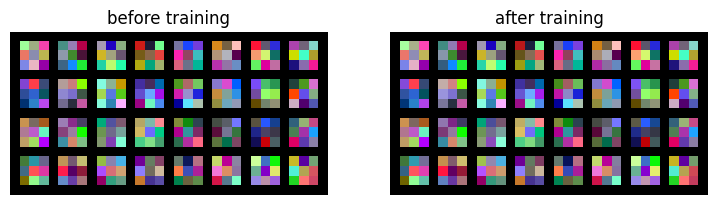

In [ ]:
# First-layer weights AFTER training: 32 filters, each 3 x 3 x 3
filters_after = model.features[0].weight.data.cpu()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, w, title in zip(
    axes,
    [filters_before, filters_after],
    ["before training", "after training"],
):
    # Tile the 32 filters into one picture, 8 per row
    grid = make_grid(w, nrow=8, normalize=True, scale_each=True, padding=1)

    # permute: C x H x W -> H x W x C for matplotlib
    ax.imshow(grid.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")

plt.show()

### Ready to Explain

- **Before training** the filters are random noise.
- **After training** expect more structure: light–dark edges and colour contrasts.
- With only 3×3 filters and a short run the change is **subtle**. If the two pictures look almost the same, the first layer has barely learned.
- **In my run** the before and after pictures look almost identical, so the first layer changed very little in 3 epochs on 10,000 images; clear edge and colour-contrast structure did not appear.
- Only the first layer is readable this way. A deeper kernel has input channels that are feature maps, not RGB colours, so it cannot be drawn as a colour image.

## **2.2 — Feature Maps**

A **forward hook** is a function that PyTorch calls automatically with a layer's output during the forward pass. Here hooks capture the activations of an early and a late layer, and every channel is shown as a grayscale image.

early layer: activation shape (32, 32, 32)
late layer: activation shape (128, 8, 8)


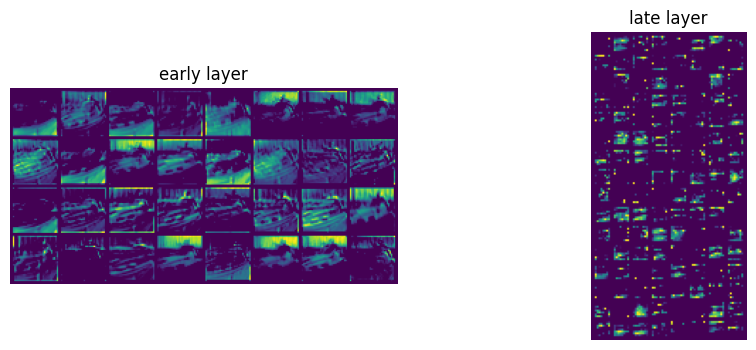

In [ ]:
# Dictionary where the hooks will store the activations
maps = {}


def save_to(name):
    # Returns a hook function that saves a layer's output under "name"
    def hook(module, inputs, output):
        # detach() removes the gradient history; we only want the values
        maps[name] = output.detach()
    return hook


# Attach hooks:
# features[1]  = ReLU after the first convolution  (early layer)
# features[13] = ReLU after the sixth convolution  (late layer)
h1 = model.features[1].register_forward_hook(save_to("early layer"))
h2 = model.features[13].register_forward_hook(save_to("late layer"))

# One forward pass; the hooks fire automatically and fill "maps"
model(x)

# Always remove hooks when finished
h1.remove()
h2.remove()


fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, A) in zip(axes, maps.items()):
    # A[0] = feature maps of the single image: channels x H x W
    print(f"{name}: activation shape {tuple(A[0].shape)}")

    # unsqueeze(1) makes each channel its own 1-channel image so make_grid can tile it
    grid = make_grid(A[0].unsqueeze(1).cpu(), nrow=8, normalize=True, scale_each=True)

    # make_grid returns 3 identical channels; show only the first
    ax.imshow(grid[0], cmap="viridis")
    ax.set_title(name)
    ax.axis("off")

plt.show()

### Ready to Explain

**shapes:** early layer **(32, 32, 32)**, late layer **(128, 8, 8)**.

- Early layer: 32 channels at the full 32×32 resolution (one conv, no pooling yet).
- Late layer: 128 channels at 8×8 (the first and second pools, after conv 2 and conv 4, halve 32 → 16 → 8 before conv 6; the third pool comes after conv 6).

**Early vs late:**
- Early maps still resemble the input: edges, outlines, colour regions.
- Late maps are smaller, coarser and sparser, and many are blank for this image, because a deep unit fires only for the pattern it is tuned to.

## **2.3 — Gradient-Based Maps with Captum**

All three methods answer "which pixels matter for this class?" with a backward pass:

- **Saliency:** absolute gradient of the class score with respect to the pixels.
- **Integrated Gradients:** accumulates gradients along a path from a blank image to the real one.
- **Guided Backpropagation:** lets only positive gradients flow back through each ReLU.

Captum needs the model, the input and the target class. The result has the input's shape (1×3×32×32), so `to_map` collapses the colour channels with a maximum.

/usr/local/lib/python3.13/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


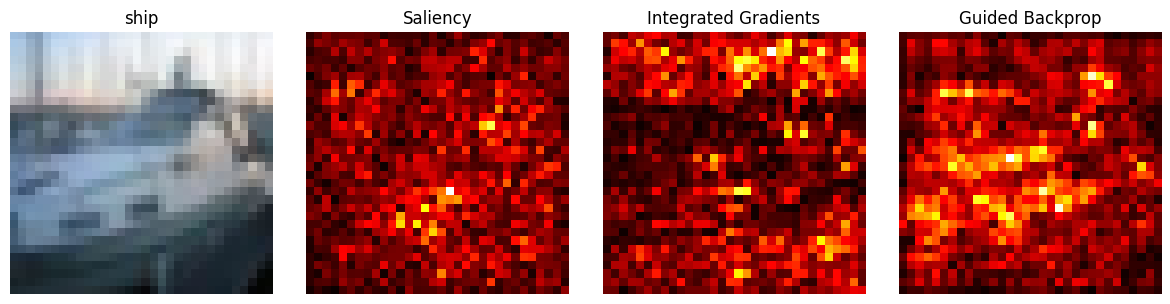

In [ ]:
def to_map(attr):
    # 1 x 3 x H x W attribution  ->  H x W map
    # abs() = size of the contribution, amax(dim=1) = strongest of the 3 colours
    return attr.abs().amax(dim=1)[0].detach().cpu()


# The three gradient-based methods (each wraps the trained model)
methods = {
    "Saliency":             Saliency(model),
    "Integrated Gradients": IntegratedGradients(model),
    "Guided Backprop":      GuidedBackprop(model),
}

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

# First panel: the original image
axes[0].imshow(show(image))
axes[0].set_title(classes[label])

for ax, (name, method) in zip(axes[1:], methods.items()):
    # ONE line per method: explain the true class "label" for image x
    attr = method.attribute(x, target=label)

    ax.imshow(to_map(attr), cmap="hot")
    ax.set_title(name)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Ready to Explain

**1. Why does `CNN` use `nn.ReLU()` layers and not `F.relu` inside `forward`?** Guided backpropagation works by hooking `nn.ReLU` **modules**. A function call has no module to hook.

**2. Sharp does not mean faithful:**
- Guided backpropagation draws clean, object-like pictures.
- But research on randomized models (Adebayo et al., 2018) found that its maps change little even when the network's weights are replaced by random ones.
- So any map should be treated as a **hypothesis** and checked against occlusion (Section 2.5).

**3. Differences in one line each:**
- **Saliency:** sensitivity of the score to each pixel (noisy).
- **Integrated Gradients:** contribution of each pixel relative to a blank baseline (about 50 times the cost of saliency).
- **Guided Backprop:** only positive evidence flows back through the ReLUs (sharp, readable).

## **2.4 — Grad-CAM and Guided Grad-CAM**

**Grad-CAM** asks which *region* of the image supported the class. It weights the feature maps of the last convolutional block by the average gradient of the class score and keeps the positive part. Its map is only as fine as that layer (8×8 here), so Captum's `interpolate` stretches it to the image size.

**Guided Grad-CAM** multiplies this coarse, class-specific map by the fine guided-backprop map, giving detail where it matters.

Grad-CAM: (1, 1, 8, 8) -> upsampled (1, 1, 32, 32)


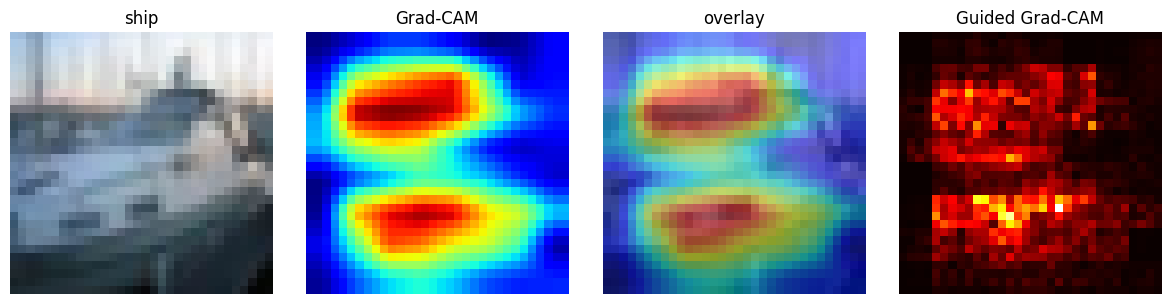

In [ ]:
# The layer to explain: last ReLU = output of the last convolutional block (8 x 8)
layer = model.features[13]

# Grad-CAM map
# relu_attributions=True keeps only POSITIVE evidence for the class
cam = LayerGradCam(model, layer).attribute(x, target=label, relu_attributions=True)

# Stretch the coarse 8 x 8 map to the image size 32 x 32
cam_up = LayerAttribution.interpolate(cam, (32, 32), interpolate_mode="bilinear")

# Guided Grad-CAM = Grad-CAM x Guided Backprop
guided_cam = GuidedGradCam(model, layer).attribute(x, target=label)

print("Grad-CAM:", tuple(cam.shape), "-> upsampled", tuple(cam_up.shape))


# 32 x 32 heat map as a plain 2D tensor
heat = cam_up[0, 0].detach().cpu()

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

axes[0].imshow(show(image))
axes[0].set_title(classes[label])

axes[1].imshow(heat, cmap="jet")
axes[1].set_title("Grad-CAM")

# Overlay: the image with the heat map drawn on top, half transparent
axes[2].imshow(show(image))
axes[2].imshow(heat, cmap="jet", alpha=0.5)
axes[2].set_title("overlay")

axes[3].imshow(to_map(guided_cam), cmap="hot")
axes[3].set_title("Guided Grad-CAM")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Ready to Explain

**Expected output:** `Grad-CAM: (1, 1, 8, 8) -> upsampled (1, 1, 32, 32)`

**1. Why is the Grad-CAM map blocky?** It is only as fine as the layer it uses. The last block has 8×8 maps, so the map is 8×8 and is only stretched (interpolated) to 32×32.

**2. Why `relu_attributions=True`?** It keeps only positive evidence for the class, as in the original method. Without it Captum also returns negative values.

**3. What does Guided Grad-CAM add?** Grad-CAM is coarse but class-specific; guided backprop is fine but not very class-specific. Multiplying them gives fine detail only inside the region that supports the class.

## **2.5 — Occlusion and the Cost of Each Method**

Occlusion needs **no gradients**. It hides a small patch, runs the network again, and records how much the class score drops. Hiding a 5×5 patch at every second pixel takes 14 × 14 = **196 forward passes** for one 32×32 image.

Occlusion map: (32, 32) | forward passes: 196


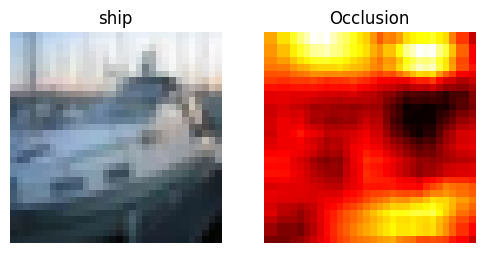

In [ ]:
# Occlusion: slide a 5x5 grey patch over the image
attr = Occlusion(model).attribute(
    x,
    target=label,
    sliding_window_shapes=(3, 5, 5),   # patch = all 3 colours, 5 x 5 pixels
    strides=(3, 2, 2),                 # slide 2 pixels at a time
    baselines=0,                       # hide the patch with grey (0 after normalization)
)

# Add the 3 colour channels into one 32 x 32 map
# bright = hiding this area LOWERS the class score
occ_map = attr[0].sum(dim=0).detach().cpu()

# Number of window positions: ((32 - 5) // 2 + 1) = 14 in each direction
print("Occlusion map:", tuple(occ_map.shape), "| forward passes:", 14 * 14)


fig, axes = plt.subplots(1, 2, figsize=(6, 3))

axes[0].imshow(show(image))
axes[0].set_title(classes[label])

axes[1].imshow(occ_map, cmap="hot")
axes[1].set_title("Occlusion")

for ax in axes:
    ax.axis("off")

plt.show()

In [ ]:
# ==========================================================
# TIME EVERY METHOD ON THE SAME IMAGE
# ==========================================================

def timed(name, run):
    # Run a function and print how long it took in milliseconds
    start = time.time()
    run()
    print(f"{name:22s} {1000 * (time.time() - start):8.1f} ms")


timed("Saliency",             lambda: Saliency(model).attribute(x, target=label))
timed("Guided Backprop",      lambda: GuidedBackprop(model).attribute(x, target=label))
timed("Grad-CAM",             lambda: LayerGradCam(model, layer).attribute(x, target=label))
timed("Integrated Gradients", lambda: IntegratedGradients(model).attribute(x, target=label))
timed("Occlusion",            lambda: Occlusion(model).attribute(
                                  x, target=label,
                                  sliding_window_shapes=(3, 5, 5), strides=(3, 2, 2)))

Saliency                    6.1 ms
Guided Backprop             4.5 ms
Grad-CAM                    2.3 ms
Integrated Gradients       20.8 ms
Occlusion                 369.6 ms


### Ready to Explain

**Expected output:** `Occlusion map: (32, 32) | forward passes: 196`

**1. Cost order (times depend on the machine, the order should not):**
- Saliency, Guided Backprop and Grad-CAM cost about **one forward and one backward pass**.
- Integrated Gradients repeats that **50 times** by default (`n_steps=50`).
- **In my run:** Saliency 6.1 ms, Guided Backprop 4.5 ms, Grad-CAM 2.3 ms, Integrated Gradients 20.8 ms, Occlusion 369.6 ms. Integrated Gradients was only about 3.4× Saliency, not 50×, because on a GPU Captum processes the 50 steps together in one batch. The order (IG above the one-pass methods, Occlusion the slowest) still holds.
- Occlusion runs **196 forward passes**.

**2. What does the extra cost buy?** Independence. Occlusion makes no assumption about the network (no gradients, no ReLU tricks), which is why it is the usual **reference** for judging the cheaper methods.

### Choosing a method

| Method | Best for | Watch out for |
|---|---|---|
| Saliency | A quick first look at pixel sensitivity | Noisy; shows sensitivity, not contribution |
| Integrated Gradients | Pixel contribution relative to a baseline | Depends on the baseline; about 50 times the cost |
| Guided Backprop | Sharp, readable pictures | Looks good even for untrained models |
| Grad-CAM | Where the class evidence is | Coarse; depends on the layer chosen |
| Guided Grad-CAM | Localized and detailed maps | Inherits guided backprop's caveat |
| Occlusion | A reference check on any model | Slow; depends on patch size and fill value |

# **Lab Exercises**

Exercises 1 to 3 are the wrap-up exercises; 4 and 5 are for practice.

## **Exercise 1 — Fan-in, fan-out and parameters: 3×3 vs 1×1 convolution (512 → 512)**

In [ ]:
# Build a 3x3 and a 1x1 convolution, both 512 -> 512 channels
for k in (3, 1):
    c = nn.Conv2d(512, 512, k)
    n_in, n_out = fans(c.weight.data)
    params = sum(p.numel() for p in c.parameters())

    print(f"{k}x{k} conv: fan_in = {n_in:5d}  fan_out = {n_out:5d}  "
          f"parameters = {params:,}  He std = {math.sqrt(2 / n_in):.4f}")

3x3 conv: fan_in =  4608  fan_out =  4608  parameters = 2,359,808  He std = 0.0208
1x1 conv: fan_in =   512  fan_out =   512  parameters = 262,656  He std = 0.0625


### Ready to Explain (Exercise 1)

| | fan-in | fan-out | parameters | He std |
|---|---:|---:|---:|---:|
| 3×3, 512 → 512 | 3·3·512 = **4,608** | 3·3·512 = **4,608** | (4,608 + 1) × 512 = **2,359,808** | √(2/4608) = 0.0208 |
| 1×1, 512 → 512 | 1·1·512 = **512** | 1·1·512 = **512** | (512 + 1) × 512 = **262,656** | √(2/512) = 0.0625 |

- **What changes:** fan-in, fan-out and the weight count all scale with the **kernel area** (9×). Parameters drop about 9×, not exactly 9×, because the bias count (512) does not change. The He std becomes 3× larger for the 1×1 layer, because each output sums fewer inputs.
- **What does not change:** the number of input and output channels (512) and the number of biases (512).
- Here fan-in = fan-out because the input and output channel counts are equal.

## **Exercise 2 — `nn.Linear(100, 100)`: Xavier vs LeCun**

In [ ]:
# A fully connected layer 100 -> 100
w = nn.Linear(100, 100).weight.data

print("fans:", fans(w))

xavier_init(w)
print("Xavier std:", round(w.std().item(), 5))

lecun_init(w)
print("LeCun  std:", round(w.std().item(), 5))

print("theory (both):", math.sqrt(1 / 100))

fans: (100, 100)
Xavier std: 0.10009
LeCun  std: 0.10032
theory (both): 0.1


### Ready to Explain (Exercise 2)

- For a Linear layer the kernel area is 1, so fan-in = fan-out = 100.
- Xavier variance = 2/(100 + 100) = 1/100 and LeCun variance = 1/100, so **they are identical** and both std values are about **0.1**.
- **Why:** whenever n_in = n_out, 2/(n_in + n_out) reduces to 1/n_in. Xavier only differs from LeCun when the layer changes the width.

## **Exercise 3 — Grad-CAM and Guided Backprop for the second most likely class**

predicted: ship | second most likely: automobile


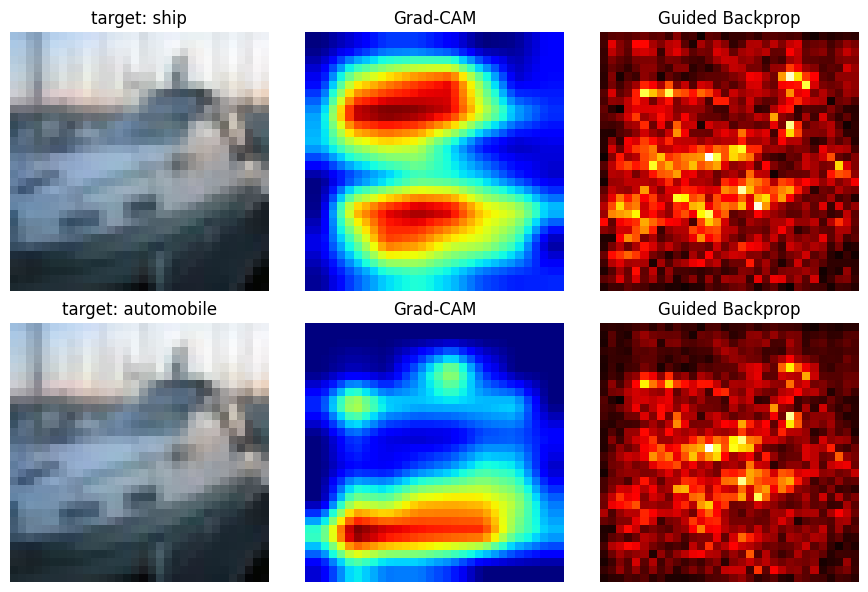

In [ ]:
# Class with the second highest score
second = model(x).topk(2).indices[0, 1].item()
print("predicted:", classes[label], "| second most likely:", classes[second])

fig, axes = plt.subplots(2, 3, figsize=(9, 6))

# Row 0 = predicted class, row 1 = second most likely class
for row, (target, title) in enumerate([(label, classes[label]), (second, classes[second])]):

    # Grad-CAM for this target class (upsampled to 32 x 32)
    c = LayerGradCam(model, layer).attribute(x, target=target, relu_attributions=True)
    c = LayerAttribution.interpolate(c, (32, 32), interpolate_mode="bilinear")

    # Guided backprop for this target class
    g = GuidedBackprop(model).attribute(x, target=target)

    axes[row, 0].imshow(show(image));                 axes[row, 0].set_title(f"target: {title}")
    axes[row, 1].imshow(c[0, 0].detach().cpu(), cmap="jet");  axes[row, 1].set_title("Grad-CAM")
    axes[row, 2].imshow(to_map(g), cmap="hot");       axes[row, 2].set_title("Guided Backprop")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

### Ready to Explain (Exercise 3)

- **Grad-CAM should move.** It uses the gradient of the chosen class score, so a different class highlights a different region (or becomes weak if the network sees little evidence for it).
- **Guided backprop should change little.** It mostly reflects the image's own edges and structure that excite the ReLUs, not the class that was asked for. This links to the Adebayo et al. warning: a sharp map is not necessarily a class-specific one.
- So Grad-CAM is **class-discriminative**, while guided backprop is mostly **image-driven**. (Judge this from your own pictures; for some images the change is small.)

## **Exercise 4 — Add BatchNorm after every convolution and rerun the activation table**

In `eval` mode a freshly built BatchNorm layer uses its default running statistics (mean 0, variance 1), so it would do nothing. To see its real effect, the network is run in **train mode**, where BatchNorm uses the statistics of the current batch.

In [ ]:
class CNNBN(nn.Module):
    # Same as CNN, but with BatchNorm after every convolution.

    def __init__(self):
        super().__init__()
        ch, layers = [3, 32, 32, 64, 64, 128, 128], []

        for i in range(6):
            layers += [nn.Conv2d(ch[i], ch[i + 1], 3, padding=1),
                       nn.BatchNorm2d(ch[i + 1]),      # <-- the only change
                       nn.ReLU()]
            if i % 2 == 1:
                layers.append(nn.MaxPool2d(2))

        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def activation_scales_bn(init_fn):
    # RMS activation after each ReLU, with BatchNorm using batch statistics.
    torch.manual_seed(0)
    model = apply_init(CNNBN(), init_fn).train()     # train mode on purpose

    h, scales = torch.randn(64, 3, 32, 32), []
    with torch.no_grad():
        for lyr in model.features:
            h = lyr(h)
            if isinstance(lyr, nn.ReLU):
                scales.append(h.pow(2).mean().sqrt().item())
    return scales


print(f"{'scheme (with BatchNorm)':24s}" + "".join(f"{'relu' + str(i + 1):>10s}" for i in range(6)))
for name, fn in inits.items():
    s = activation_scales_bn(fn)
    print(f"{name:24s}" + "".join(f"{v:10.2e}" for v in s))

scheme (with BatchNorm)      relu1     relu2     relu3     relu4     relu5     relu6
PyTorch default           7.07e-01  7.07e-01  7.09e-01  7.08e-01  7.05e-01  7.07e-01
LeCun                     7.07e-01  7.06e-01  7.07e-01  7.07e-01  7.08e-01  7.08e-01
Xavier                    7.07e-01  7.06e-01  7.07e-01  7.07e-01  7.08e-01  7.08e-01
He                        7.07e-01  7.06e-01  7.07e-01  7.07e-01  7.08e-01  7.08e-01
std = 0.01                7.05e-01  7.05e-01  7.07e-01  7.07e-01  7.08e-01  7.08e-01


### Ready to Explain (Exercise 4)

- With BatchNorm, **every row becomes nearly the same**, including the **std = 0.01** and **PyTorch default** rows that collapsed before. The RMS stays of order 1 at every layer (about 0.707 = √0.5 at every layer, which is the mean square of a ReLU applied to a unit-variance input).
- **Why:** BatchNorm re-normalizes the output of every convolution to zero mean and unit variance, so whatever scale the weights produced is removed before the ReLU.
- **What it proves:** initialization only decides the signal scale **when nothing else corrects it**. BatchNorm takes over that job, which is why VGG-lite used BatchNorm in the CNN-architectures practical and why plain deep ReLU stacks depend so strongly on He initialization. Initialization still helps gradients and early training, but it is no longer critical for the scale.

## **Exercise 5 — Occlusion window size: 3×3, 5×5 and 10×10**

window  3x3 : 225 forward passes,   331.1 ms


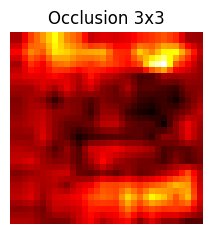

window  5x5 : 196 forward passes,   280.4 ms


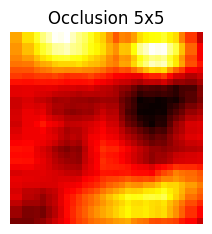

window 10x10: 144 forward passes,   179.7 ms


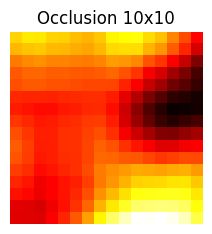

In [ ]:
for k in (3, 5, 10):

    start = time.time()

    # Slide a k x k patch, 2 pixels at a time
    a = Occlusion(model).attribute(
        x, target=label,
        sliding_window_shapes=(3, k, k),
        strides=(3, 2, 2),
        baselines=0,
    )

    # Number of positions in each direction = (32 - k) // 2 + 1
    n = (32 - k) // 2 + 1
    ms = 1000 * (time.time() - start)

    print(f"window {k:2d}x{k:<2d}: {n * n:3d} forward passes, {ms:7.1f} ms")

    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(a[0].sum(dim=0).detach().cpu(), cmap="hot")
    plt.title(f"Occlusion {k}x{k}")
    plt.axis("off")
    plt.show()

### Ready to Explain (Exercise 5)

| Window | Forward passes ((32 − k)//2 + 1)² | Map |
|---|---:|---|
| 3×3 | 15² = **225** | Fine detail but noisy; one tiny patch rarely changes the score much |
| 5×5 | 14² = **196** | Balanced |
| 10×10 | 12² = **144** | Smooth and blurry; a big patch hides whole parts at once |

- **Cost:** a smaller window gives more positions and so more passes (slightly slower), though the time is also affected by how many pixels each pass changes.
- **Most informative:** usually the middle size (5×5): small enough to localize, large enough to remove a meaningful feature.
- **Trade-off:** small patches give **precise location but weak signal**; large patches give **strong signal but poor location**.

# **Viva Questions**

**1. A 5×5 convolution with 16 input and 32 output channels has 12,832 parameters. Which number enters the He formula, and why?**
- The fan-in, **400** (5 × 5 × 16), not 12,832.
- Fan-in is the number of weights that reach ONE output value, and that is what sets the variance of the sum. The parameter count includes all 32 filters and the biases.
- He std = √(2/400) ≈ 0.0707.

**2. Where does the 2 in Xavier come from, and where does the 2 in He come from? Are they related?**
- **Xavier:** the forward pass wants Var = 1/n_in and the backward pass wants 1/n_out. The compromise is 1/((n_in + n_out)/2) = **2/(n_in + n_out)**, so the 2 comes from *averaging* the two fans.
- **He:** the 2 compensates for the ReLU, which zeroes half the signal and halves the mean square.
- They are **not related**. It is a coincidence of notation (although both reduce to 1/n_in or 2/n_in in the simple cases).

**3. PyTorch has no LeCun initializer. How do you get one, and why is a freshly constructed `nn.Conv2d` not He-initialized?**
- LeCun = `nn.init.kaiming_normal_(w, nonlinearity="linear")` (or `kaiming_uniform_`), because gain 1 gives variance 1/n_in.
- A new `nn.Conv2d` uses `kaiming_uniform_(w, a=math.sqrt(5))`, i.e. std = 1/√(3·n_in), which is √6 times narrower than He. It is a legacy default that works acceptably for shallow networks. For He, call the initializer yourself.

**4. With std = 0.01 nothing overflows and no NaN appears, yet the network does not train. Explain.**
- The activation scale shrinks at every layer (to about 1e-6 by the sixth ReLU), so the classifier receives essentially zeros and every output is close to the bias.
- The gradients are tiny for the same reason: they are multiplied by small weights on the way back, so the early layers barely get an update.
- Nothing is numerically broken, so there is no error. The network sits on a flat plateau near chance (about 10%) and learns extremely slowly.

**5. Saliency, Grad-CAM and occlusion each answer a different question. State each question, and say which method you would trust most and why.**
- **Saliency:** which pixels would change the class score most if nudged? (local sensitivity)
- **Grad-CAM:** which region of the image supports the class? (coarse, class-specific evidence)
- **Occlusion:** how much does the score drop when this patch is hidden? (actual effect on the output)
- **Trust most: occlusion**, because it measures the real change in the score, makes no assumption about the network and uses no gradients. Its limits are cost and the choice of patch size and fill value. The cheaper methods are best checked against it.